In [1]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor, Lambda, Compose
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch.nn.functional as F
import math

In [2]:
from google.colab import drive
drive.mount('/content/drive')  # mount Drive vào /content/drive



Mounted at /content/drive


In [3]:
!cp -r '/content/drive/MyDrive/Car racing  2025/Data/Dataset_round2' dataround2

In [6]:
!unzip /content/dataround2/Dataset_round2_v1_coco.zip -d /content/datav1

Archive:  /content/dataround2/Dataset_round2_v1_coco.zip
  inflating: /content/datav1/README.dataset.txt  
  inflating: /content/datav1/README.roboflow.txt  
   creating: /content/datav1/train/
  inflating: /content/datav1/train/_annotations.coco.json  
 extracting: /content/datav1/train/frame_1759585375_9080615_png.rf.636f43f67f8bae8026dac0ed812c63b9.jpg  
 extracting: /content/datav1/train/frame_1759585375_9080615_png.rf.6a8d535466cbca0913ae8bc4a60d9217.jpg  
 extracting: /content/datav1/train/frame_1759585375_9080615_png.rf.a8c805c9dff70d7b32907a29c9635878.jpg  
 extracting: /content/datav1/train/frame_1759585377_4431424_png.rf.1cc16771e9ecb3e2d514a69e78c1225b.jpg  
 extracting: /content/datav1/train/frame_1759585377_4431424_png.rf.3358d5e9052a561376cbc9213793cac9.jpg  
 extracting: /content/datav1/train/frame_1759585377_4431424_png.rf.e99ec837aead64946d72b7082ebc1822.jpg  
 extracting: /content/datav1/train/frame_1759585379_5842304_png.rf.16a132cc341fbb7154da4489dc17868b.jpg  
 ext

In [7]:
!unzip /content/dataround2/Dataset_v2.zip -d /content/datav2

Archive:  /content/dataround2/Dataset_v2.zip
  inflating: /content/datav2/README.dataset.txt  
  inflating: /content/datav2/README.roboflow.txt  
   creating: /content/datav2/train/
  inflating: /content/datav2/train/_annotations.coco.json  
 extracting: /content/datav2/train/frame_1759585817_578948_png.rf.115a430ab4963af4ebc7bf78443615c8.jpg  
 extracting: /content/datav2/train/frame_1759585817_578948_png.rf.52deb730276c66630f186c81bd0a4533.jpg  
 extracting: /content/datav2/train/frame_1759585817_578948_png.rf.ed38d50b2754bc72be39167b8f71e0f7.jpg  
 extracting: /content/datav2/train/frame_1759585818_1719246_png.rf.59d234b76f5a7df3fe491f0057c1ac4c.jpg  
 extracting: /content/datav2/train/frame_1759585818_1719246_png.rf.c9ca349a71011258e3c1df2b5b07741b.jpg  
 extracting: /content/datav2/train/frame_1759585818_7629228_png.rf.15b7c4cdb97b9a4f28a9e4e7fac748bc.jpg  
 extracting: /content/datav2/train/frame_1759585818_7629228_png.rf.1f2c969d0426e7a58d45b2653a491f1a.jpg  
 extracting: /conte

#Dataset

In [8]:
from torch.utils.data import Dataset, DataLoader
import os
import PIL


In [9]:
import json
import os
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset

class JSONDataset(Dataset):
    def __init__(self, imgs_dir, json_path, transform=None):
        self.imgs_dir = imgs_dir
        self.transform = transform

        with open(json_path) as f:
            data = json.load(f)

        self.images_info = {img['id']: img for img in data['images']}
        self.annotations = {}
        for ann in data['annotations']:
            img_id = ann['image_id']
            if img_id not in self.annotations:
                self.annotations[img_id] = []
            self.annotations[img_id].append(ann)

        self.img_ids = list(self.images_info.keys())

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img_info = self.images_info[img_id]
        img_path = os.path.join(self.imgs_dir, img_info['file_name'])

        # === Dùng OpenCV đọc ảnh (BGR -> RGB) ===
        img = cv2.imread(img_path)
        if img is None:
            raise FileNotFoundError(f"Không tìm thấy ảnh: {img_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_np = img.copy()

        MAX_BBOX = 5
        annots = self.annotations.get(img_id, [])
        bboxes = torch.zeros((MAX_BBOX, 5), dtype=torch.float32)

        # Giữ nguyên logic i >= 2
        for i, ann in enumerate(annots[:MAX_BBOX]):
            if i >= 2:
                x_min, y_min, w, h = ann['bbox']
                x_max = x_min + w
                y_max = y_min + h
                y_max *= 192 / 180
                y_min *= 192 / 180
                target_row = i - 2
                if target_row < MAX_BBOX:
                    bboxes[target_row] = torch.tensor(
                        [1, x_min, y_min, x_max, y_max], dtype=torch.float32
                    )

        # === MASK bằng OpenCV ===
        mask = np.zeros((180, 320), dtype=np.uint8)

        for ann in annots:
            if ann['category_id'] == 1 and 'segmentation' in ann:
                for seg in ann['segmentation']:
                    pts = np.array(seg, dtype=np.int32).reshape(-1, 2)
                    cv2.fillPoly(mask, [pts], color=1)

        # === APPLY TRANSFORM cho cả image & mask cùng lúc ===
        if self.transform:
            augmented = self.transform(image=img_np, mask=mask)
            img, mask = augmented["image"], augmented["mask"]

        # === Chuyển sang tensor ===

        mask = (mask).unsqueeze(0).float()
        # img_np = (img).permute(2, 0, 1).float() / 255.0
        sample = {
            "detect": bboxes,
            "segment": mask
        }

        return img, sample


In [10]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
train_transform = A.Compose([
    A.Resize(192, 320),
    A.Normalize(),
    ToTensorV2(),
])
val_transform = A.Compose([
    A.Resize(192, 320),
    A.Normalize(),
    ToTensorV2(),
])

In [11]:
dataset1 = JSONDataset(imgs_dir='/content/datav1/train', json_path='/content/datav1/train/_annotations.coco.json', transform = train_transform)

In [12]:
dataset1[1][0].shape

torch.Size([3, 192, 320])

In [13]:
dataset1[1][1]['segment'].shape

torch.Size([1, 192, 320])

In [14]:
dataloader1 = DataLoader(dataset1, batch_size=4, shuffle=True)

(180, 320, 3)


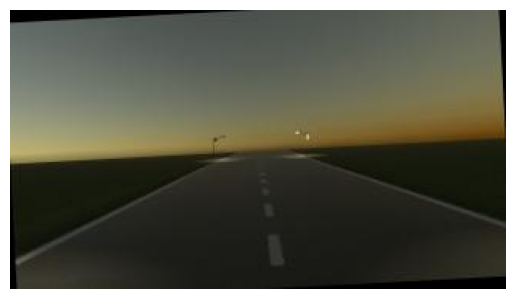

In [15]:
import cv2
import matplotlib.pyplot as plt # Import matplotlib

image = cv2.imread('/content/datav1/train/frame_1759585375_9080615_png.rf.6a8d535466cbca0913ae8bc4a60d9217.jpg')

# Convert BGR to RGB for proper display with matplotlib
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
print(image.shape)
# Display the image
plt.imshow(image)
plt.axis('off') # Turn off axis numbers and ticks
plt.show()

In [17]:
from PIL import ImageDraw, Image

def visualize_bbox(img: Image.Image, bboxes):
    # Tạo đối tượng vẽ
    draw = ImageDraw.Draw(img)

    for bbox in bboxes:
        score, x_min,y_min, x_max, y_max = bbox.tolist()
        if score == 1:  # chỉ vẽ nếu có bbox
            draw.rectangle(
                [(x_min, y_min), (x_max, y_max)],
                outline="red", width=6
            )

    return img # Trả về ảnh đã vẽ

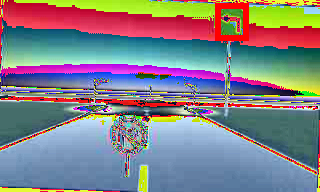

In [18]:
from PIL import Image
import numpy as np # Import numpy
from torchvision.transforms import ToPILImage # Import ToPILImage

# Convert the tensor back to a PIL Image using ToPILImage
# Assuming the image tensor is normalized between 0 and 1
to_pil = ToPILImage()
img_pil = to_pil(dataset1[2][0])


# Pass the PIL Image to visualize_bbox and display the result
visualized_image = visualize_bbox(img_pil, dataset1[2][1]['detect'])
display(visualized_image)

#Model

In [20]:
class ResidualBottleneck(nn.Module):
    def __init__(self, in_ch, out_ch, expansion_rate=6, stride=1):
        super().__init__()
        mid_ch = in_ch * expansion_rate

        # 1. Pointwise conv (expansion)
        self.pwconv = nn.Conv2d(in_ch, mid_ch, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_ch)
        self.act1 = nn.ReLU6(inplace=True)

        # 2. Depthwise conv
        self.dwconv = nn.Conv2d(mid_ch, mid_ch, kernel_size=3, stride=stride, padding=1, groups=mid_ch, bias=False)
        self.bn2 = nn.BatchNorm2d(mid_ch)
        self.act2 = nn.ReLU6(inplace=True)

        # 3. Pointwise conv (projection) → linear (no activation)
        self.pwconv2 = nn.Conv2d(mid_ch, out_ch, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn3 = nn.BatchNorm2d(out_ch)

        # Residual connection nếu stride=1 và in_ch == out_ch
        self.use_residual = (stride == 1 and in_ch == out_ch)

    def forward(self, x):
        out = self.act1(self.bn1(self.pwconv(x)))
        out = self.act2(self.bn2(self.dwconv(out)))
        out = self.bn3(self.pwconv2(out))

        if self.use_residual:
            out = x + out  # inverted residual connection
        return out
class Encoder(nn.Module):
  def __init__(self, input_ch, alpha = 1):
    super().__init__()
    self.input_ch = input_ch
    self.alpha = alpha
    self.enc1 = nn.Sequential(
        nn.Conv2d(in_channels = input_ch, out_channels = int(32*alpha), kernel_size=3, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(int(32*alpha)),
        nn.ReLU6(inplace=True)
    )

    self.enc2 = nn.Sequential(
        ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(16*alpha), expansion_rate = 1, stride = 1),
        nn.BatchNorm2d(int(16*alpha))#192*320
    )
    self.enc3 = nn.Sequential(
        ResidualBottleneck(in_ch = int(16*alpha), out_ch = int(24*alpha), expansion_rate = 6, stride = 2),
        ResidualBottleneck(in_ch = int(24*alpha), out_ch = int(24*alpha), expansion_rate = 6, stride = 1),
        nn.BatchNorm2d(int(24*alpha))
    )
    self.enc4 = nn.Sequential(
        ResidualBottleneck(in_ch = int(24*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 2),
        ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 1),
        ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 1),
        nn.BatchNorm2d(int(32*alpha))
    )
    self.enc5 = nn.Sequential(
        ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 2),
        ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
        ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
        ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
        nn.BatchNorm2d(int(64*alpha))
    )
    self.enc6 = nn.Sequential(
        ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
        ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
        ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
        nn.BatchNorm2d(int(96*alpha))
    )
    self.enc7 = nn.Sequential(
        ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 2),
        ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 1),
        ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 1),
        nn.BatchNorm2d(int(160*alpha))
    )
    self.enc8 = nn.Sequential(
        ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(320*alpha), expansion_rate = 6, stride = 1),
        nn.BatchNorm2d(int(320*alpha))
    )
    # chia 2^5
    self.enc9 = nn.Sequential(
        nn.Conv2d(int(320*alpha), int(1280*alpha), kernel_size=1, stride=1, padding=0, bias=False),
        nn.BatchNorm2d(int(1280*alpha))
    )

  def forward(self, x):
      x = self.enc1(x)
      x = self.enc2(x)
      x = self.enc3(x)
      x = self.enc4(x)
      x = self.enc5(x)
      x = self.enc6(x)
      x = self.enc7(x)
      x = self.enc8(x)
      x = self.enc9(x)
      return x



In [21]:
class DecoderSegment(nn.Module):
  def __init__(self, out_ch = 1, alpha = 1):
    super().__init__()
    self.out_ch = out_ch
    self.alpha = alpha
    self.up1 = nn.Sequential(
            nn.ConvTranspose2d(int(1280*alpha), int(320*alpha), 2, stride=2),
            nn.BatchNorm2d(int(320*alpha)),
            nn.PReLU()
        )
    self.up2 = nn.Sequential(
        nn.ConvTranspose2d(int(320*alpha), int(160*alpha), 2, stride=2),
        nn.BatchNorm2d(int(160*alpha)),
        nn.ReLU6(inplace = True)
    )
    self.up3 = nn.Sequential(
        nn.ConvTranspose2d(int(160*alpha), int(64*alpha), 2, stride=2),
        nn.BatchNorm2d(int(64*alpha)),
        nn.ReLU6(inplace = True)
    )
    self.up4 = nn.Sequential(
        nn.ConvTranspose2d(int(64*alpha), int(32*alpha), 2, stride=2),
        nn.BatchNorm2d(int(32*alpha)),
        nn.ReLU6(inplace = True)
    )
    self.up5 = nn.Sequential(
        nn.ConvTranspose2d(int(32*alpha),int(24*alpha), 2, stride=2),
        nn.BatchNorm2d(int(24*alpha)),
        nn.ReLU6(inplace = True)
    )
    self.final = nn.Conv2d(int(24*alpha), out_ch, kernel_size=1,padding=0, bias=False)
  def forward(self, x):
    x = self.up1(x)
    x = self.up2(x)
    x = self.up3(x)
    x = self.up4(x)
    x = self.up5(x)
    x = self.final(x)
    return x



In [22]:
class PAM(nn.Module):
    """Position Attention Module (spatial attention)"""
    def __init__(self, in_channels, reduction=8, use_bn=True):
        super().__init__()
        self.in_ch = in_channels
        self.inter_ch = in_channels // reduction
        # Query / Key / Value conv + BN
        self.query_conv = nn.Sequential(
            nn.Conv2d(in_channels, self.inter_ch, 1, bias=False),
            nn.BatchNorm2d(self.inter_ch) if use_bn else nn.Identity()
        )
        self.key_conv = nn.Sequential(
            nn.Conv2d(in_channels, self.inter_ch, 1, bias=False),
            nn.BatchNorm2d(self.inter_ch) if use_bn else nn.Identity()
        )
        self.value_conv = nn.Sequential(
            nn.Conv2d(in_channels, self.inter_ch, 1, bias=False),
            nn.BatchNorm2d(self.inter_ch) if use_bn else nn.Identity()
        )
        # project back
        self.out_conv = nn.Sequential(
            nn.Conv2d(self.inter_ch, in_channels, 1, bias=False),
            nn.BatchNorm2d(in_channels) if use_bn else nn.Identity()
        )
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        N = H * W

        q = self.query_conv(x).view(B, self.inter_ch, N).permute(0, 2, 1)  # (B, N, d)
        k = self.key_conv(x).view(B, self.inter_ch, N)                     # (B, d, N)
        energy = torch.bmm(q, k)  # (B, N, N)
        # scaled dot-product (optional, helps when d large)
        energy = energy / math.sqrt(self.inter_ch)
        attention = F.softmax(energy, dim=-1)  # rows sum to 1 (for each target j)
        v = self.value_conv(x).view(B, self.inter_ch, N)  # (B, d, N)

        out = torch.bmm(v, attention.permute(0, 2, 1))  # (B, d, N) -> each j gets sum_i s_ji * v_i
        out = out.view(B, self.inter_ch, H, W)
        out = self.out_conv(out)  # back to C
        return x + self.gamma * out  # residual

class AttentionBlock(nn.Module):
  def __init__(self, in_ch = 1280, out_ch = 320):
    super().__init__()
    self.pointwise = nn.Sequential(
        nn.Conv2d(in_channels = in_ch, out_channels = out_ch, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(inplace=True)
    )
    self.PAM = PAM(in_channels = out_ch, reduction=8, use_bn=True)
  def forward(self, x):
    x = self.pointwise(x)
    x = self.PAM(x)
    x = self.PAM(x)
    x = self.PAM(x)
    return x

In [23]:
import torch
import torch.nn as nn

class DecoderDetect(nn.Module):
  def __init__(self, in_ch = 320, out_class = 4):
    super().__init__()
    self.out_class = out_class
    self.pointwise = nn.Sequential(
        nn.Conv2d(in_channels = in_ch, out_channels = 80, kernel_size=1, stride=1, padding=0, bias=True),
        nn.BatchNorm2d(80),
        nn.LeakyReLU(inplace=True)
    )
    self.flatten = nn.Sequential(
        nn.Flatten(),
        )
    # Linear layer to output 5 bounding boxes, each with 5 values (score, x1, y1, x2, y2)
    self.fc = nn.Linear(in_features= 80 * 6 * 10, out_features = 5 * 5) # Assuming spatial dim (6, 10) after encoder/attention

  def forward(self, x):
    x = self.pointwise(x)
    x = self.flatten(x)
    x = self.fc(x)
    # Reshape to (Batch_size, num_bboxes, bbox_params)
    return x.view(x.size(0), 5, 5)

In [24]:
class model_V2(nn.Module):
  def __init__(self, in_ch, out_ch, out_class = 4,alpha = 1):
    super().__init__()
    self.encoder = Encoder(input_ch = in_ch, alpha = alpha)
    self.segmentor = DecoderSegment(out_ch = out_ch, alpha = alpha)
    self.attention = AttentionBlock(in_ch = int(1280*alpha), out_ch = int(320*alpha))
    self.detector = DecoderDetect(in_ch = int(320*alpha), out_class = out_class)
  def forward(self, x):
    x = self.encoder(x)
    segment = self.segmentor(x)
    att = self.attention(x)
    detect = self.detector(att)
    dict = {"segment": segment, "detect": detect}
    return dict

In [25]:
model = model_V2(in_ch = 3, out_ch = 1, alpha = 0.75)

In [26]:
x = torch.randn(1,3, 192, 320)   # shape (1,3,192,320)
y = model(x)
print(f"segment: {y['segment'].shape}")
print(f"detect: {y['detect'].shape}")

segment: torch.Size([1, 1, 192, 320])
detect: torch.Size([1, 5, 5])


In [27]:
!pip install thop

In [28]:
import torch
import torch.nn as nn
from thop import profile

def count_params_flops(model, input_size=(1, 3, 192, 320)):
    dummy_input = torch.randn(*input_size)
    flops, params = profile(model, inputs=(dummy_input, ), verbose=False)
    return {
        "FLOPs": flops,
        "Params": params
        }
print(count_params_flops(model))

{'FLOPs': 875971680.0, 'Params': 2738810.0}


/usr/local/lib/python3.12/dist-packages/thop/vision/calc_func.py:53: UserWarning: This API is being deprecated
  warnings.warn("This API is being deprecated")


#Loss Function

In [32]:
#loss segment
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-4): # Increased smooth value
        super().__init__()
        self.smooth = smooth
    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)  # logits -> prob
        preds = preds.view(-1)
        targets = targets.view(-1).float().clamp(0,1) # Clamping targets
        intersection = (preds * targets).sum()
        # Added 1e-6 for denominator stability and clamped Dice coefficient
        dice = (2.*intersection + self.smooth) / (preds.sum() + targets.sum() + self.smooth + 1e-6)
        dice = torch.clamp(dice, 0, 1) # Clamp dice coefficient to be between 0 and 1
        return 1 - dice

class BCE_DiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
    def forward(self, preds, targets):
        # Remove the incorrect unsqueeze (already removed)
        # BCE loss should be non-negative. Dice loss should be non-negative after clamping.
        return self.bce(preds, targets.float()) + self.dice(preds, targets)

In [64]:
import torch
import torch.nn as nn
from torchvision.ops import box_iou

class LossBoundingBoxYOLO(nn.Module):
    def __init__(self, img_size=(320,192), eps=1e-6):
        super().__init__()
        self.img_w, self.img_h = img_size
        self.eps = eps

    def forward(self, bbox, targets):
        """
        bbox, targets: [B, N, 5] -> [conf, x1, y1, x2, y2]
        """
        B, N, _ = bbox.shape
        total_loss = 0

        for i in range(B):
            # --- confidence coefficient ---
            pred_conf = torch.sigmoid(bbox[i, :, 0])
            target_conf = targets[i, :, 0].float().clamp(0,1)
            coff = pred_conf * target_conf  # stable gradient

            # --- prepare bbox (clone để tránh in-place) ---
            bbox_pred = bbox[i, :, 1:].clone()
            bbox_target = targets[i, :, 1:].clone()

            # --- clamp và convert bbox chuẩn ---
            x1 = bbox_pred[:,0].clamp(0, self.img_w)
            y1 = bbox_pred[:,1].clamp(0, self.img_h)
            x2 = torch.max(bbox_pred[:,2].clamp(0, self.img_w), x1 + self.eps)
            y2 = torch.max(bbox_pred[:,3].clamp(0, self.img_h), y1 + self.eps)
            bbox_pred_adjusted = torch.stack([x1, y1, x2, y2], dim=1)

            x1_t = bbox_target[:,0].clamp(0, self.img_w)
            y1_t = bbox_target[:,1].clamp(0, self.img_h)
            x2_t = torch.max(bbox_target[:,2].clamp(0, self.img_w), x1_t + self.eps)
            y2_t = torch.max(bbox_target[:,3].clamp(0, self.img_h), y1_t + self.eps)
            bbox_target_adjusted = torch.stack([x1_t, y1_t, x2_t, y2_t], dim=1)

            # --- compute IoU ---
            iou_matrix = box_iou(bbox_pred_adjusted, bbox_target_adjusted)
            iou_diag = torch.diag(iou_matrix).clamp(min=self.eps, max=1.0)

            # --- bbox loss per image ---
            loss_bbox_per_image = (1 - iou_diag) * coff
            total_loss += loss_bbox_per_image.mean()

        return total_loss / B



class LossDetect(nn.Module):
    def __init__(self, w1=3.0, w2=1.0):
        super().__init__()
        self.w1 = w1
        self.w2 = w2
        self.loss_bbox = LossBoundingBoxYOLO()
        self.CE = nn.BCEWithLogitsLoss()  # expects logits

    def forward(self, bbox, targets):
        # bbox, targets: [B, N, 5]
        # Bbox loss
        loss_bbox_total = self.loss_bbox(bbox, targets)

        # BCE loss cho confidence scores
        pred_conf = bbox[:, :, 0].view(-1)                      # logits trực tiếp, không sigmoid
        target_conf = targets[:, :, 0].view(-1).float().clamp(0,1)  # float + clamp [0,1]

        loss_CE = self.CE(pred_conf, target_conf)

        return self.w1 * loss_bbox_total + self.w2 * loss_CE


In [65]:
class synLoss(nn.Module):
  def __init__(self):
    super().__init__()
    self.loss_bbox = LossDetect()
    self.loss_segment = BCE_DiceLoss()
  def forward(self, sample_train, sample_targets):
    loss_bbox = self.loss_bbox(sample_train['detect'], sample_targets['detect'])
    print(loss_bbox)
    loss_CE = self.loss_segment(sample_train['segment'], sample_targets['segment'])
    print(loss_CE)
    return loss_bbox + loss_CE


In [66]:
loss = synLoss()
# Pass the dictionary containing the target 'detect' and 'segment'
# dataset1[0] returns (image_tensor, sample_dict)
batch = next(iter(dataloader1))

# Move the image tensor to the device
image_on_device = batch[0].to('cuda')

# Move target tensors in the dictionary to the device
targets_on_device = {key: val.to("cuda") for key, val in batch[1].items()}

# Pass the tensors on the device to the model and loss function
loss(model(image_on_device), targets_on_device)

tensor(0.6127, device='cuda:0', grad_fn=<AddBackward0>)
tensor(1.3212, device='cuda:0', grad_fn=<AddBackward0>)


tensor(1.9339, device='cuda:0', grad_fn=<AddBackward0>)

In [67]:
model(batch[0])['detect']

RuntimeError: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor

#Training

In [68]:
#both training
def train_both(model, train_loader, device, epochs=10):
    # Enable anomaly detection for detailed error messages

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = synLoss()
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for imgs, samples in train_loader:
            # samples is already a dictionary containing 'segment' and 'detect'
            # masks = samples['segment'] # No longer need to extract masks separately here
            imgs = imgs.to(device)
            # Move target tensors in the dictionary to the device
            samples_on_device = {key: val.to(device) for key, val in samples.items()}


            optimizer.zero_grad()
            # model returns a dictionary of predictions
            predictions = model(imgs)

            # Pass both prediction and target dictionaries to the loss function
            loss = loss_fn(predictions, samples_on_device)
            loss.backward(retain_graph=True)
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")

In [69]:
train_both(model = model, train_loader = dataloader1, device = 'cuda', epochs = 10)

Streaming output truncated to the last 5000 lines.
tensor(0.0069, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0873, device='cuda:0', grad_fn=<AddBackward0>)
tensor(2.6703e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0735, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1189, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1134, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1200, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.6035, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0034, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0789, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0074, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0536, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1063, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0628, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1077, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0712, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1247, device='cuda:0', grad_fn=<AddBackw

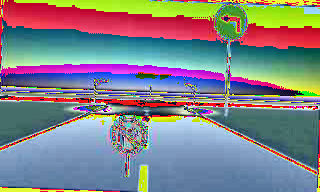

In [72]:
to_pil = ToPILImage()
img_tensor = dataset1[2][0]

# Add a batch dimension to the image tensor
img_tensor_with_batch = img_tensor.unsqueeze(0)

# Move the image tensor with batch dimension to the device where the model is
device = next(model.parameters()).device
img_tensor_on_device = img_tensor_with_batch.to(device)

# Convert the original CPU image tensor to PIL Image for visualization (for visualization)
# Note: Visualization is typically done on CPU. We'll process with the model on device,
# then move the output back to CPU for visualization if necessary.
# For now, let's just ensure the model call works by moving input to device.
# If visualization requires CPU, we'll handle model output later.
model.eval()
with torch.no_grad(): # Use no_grad for inference
    # Pass the image tensor on the device to the model
    model_output = model(img_tensor_on_device)
    # Get the detection output (bboxes)
    bboxes_output = model_output['detect']

# Move the bounding box output back to CPU for visualization with PIL
bboxes_output_cpu = bboxes_output.cpu()

# Convert the original CPU image tensor to PIL Image for visualization
img_pil = to_pil(img_tensor)


# Pass the PIL Image and the CPU bounding box output to visualize_bbox
visualized_image = visualize_bbox(img_pil, bboxes_output_cpu)
display(visualized_image)

In [73]:
bboxes_output_cpu

tensor([[[-5.1258e-01,  1.0449e-02,  5.6208e-02,  3.0190e-02, -2.9327e-03],
         [-8.8510e+00,  1.1399e-01,  1.2085e-01, -2.9129e-02,  6.5792e-02],
         [-8.7377e+00, -9.4405e-02, -1.6446e-01, -3.5002e-01,  9.9168e-02],
         [-9.0903e+00, -1.6051e-02, -3.2498e-02,  1.6475e-01,  2.2456e-02],
         [-8.5579e+00,  9.3249e-02, -3.5203e-02,  3.8503e-02,  1.7362e-01]]])

In [221]:
#train segment first
def train_segment(model, train_loader, device, epochs=10):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)
    loss_fn = BCE_DiceLoss()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)

            optimizer.zero_grad()
            segment = model(imgs)["segment"]
            loss = loss_fn(segment, masks)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            #scheduler.step()

        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")

In [ ]:
#freezing some layer after train segment done
def freeze_encoder(model):
    for param in model.encoder.parameters():
        param.requires_grad = False
    for param in model.segmentor.parameters():
        param.requires_grad = False



In [ ]:
def train_segment(model, train_loader, device, epochs=10):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = LossDetect()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)

            optimizer.zero_grad()
            bbox = model(imgs)["detect"]
            loss = loss_fn(bbox, masks)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            #scheduler.step()

        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")

In [ ]:
x = torch.randn(1, 3, 192, 320)   # shape (1,3,192,320)
y = model(x)
loss_test_detect = LossDetect()
loss_test_segment = BCE_DiceLoss()
targets_test = torch.randn(4, 5)
targets_test[:,0] = torch.sigmoid(targets_test[:,0])
segment_test = torch.randn(1, 192, 320)
print(segment_test.shape)
print(targets_test)
loss_detect = loss_test_detect(y['detect'], targets_test)
loss_segment = loss_test_segment(y['segment'], segment_test)
print(loss_detect, loss_segment)

torch.Size([1, 192, 320])
tensor([[ 0.6634, -0.4140, -0.9857,  0.3587,  0.7147],
        [ 0.1107,  0.2260,  1.2282,  1.1412,  1.0803],
        [ 0.6376,  0.4680, -0.8168, -0.7080,  0.6402],
        [ 0.3172,  0.9032, -0.2950, -0.6223,  1.0067]])
tensor(1.0340, grad_fn=<AddBackward0>) tensor(1.7393, grad_fn=<AddBackward0>)


#Dataset

In [ ]:
from torch.utils.data import Dataset, DataLoader
import os
class SegmentDataset(Dataset):
  def __init__(self, imgs_path, masks_path, transform = None):
    self.imgs_path = imgs_path
    self.masks_path = masks_path
    self.images = os.listdir(imgs_path)
    self.transform = transform

  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    img_path = os.path.join(self.imgs_path, self.images[idx])
    mask_path = os.path.join(self.masks_path, self.images[idx])
    image = cv2.imread(img_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    # Add checks for None
    if image is None:
        print(f"Warning: Could not read image file: {img_path}")
        return None, None # Or handle this case appropriately, e.g., skip

    if mask is None:
        print(f"Warning: Could not read mask file: {mask_path}")
        return None, None # Or handle this case appropriately, e.g., skip


    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


    if self.transform:
        augmented = self.transform(image=image, mask=mask)
        image, mask = augmented["image"], augmented["mask"]

    # Ensure mask is a tensor and convert to long type with binary values
    mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization
    mask = (mask > 127).long() # Binarize and convert to long

    return image, mask

class DetectDataset(Dataset):
  def __init__(self, imgs_path, masks_path, transform = None):
    self.imgs_path = imgs_path
    self.masks_path = masks_path
    self.images = os.listdir(imgs_path)
    self.transform = transform

